<a href="https://colab.research.google.com/github/ummugulsumciftci/GROUP30_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys, subprocess

GITHUB_USER = "ummugulsumciftci"
REPO_DIR = "GROUP30_CENG313"
REPO_PATH = f"/content/{REPO_DIR}"

if not os.path.exists(REPO_PATH):
    url = f"https://github.com/{GITHUB_USER}/{REPO_DIR}.git"
    try:  # private repo -> token from Colab secrets
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{GITHUB_USER}/{REPO_DIR}.git"
    except Exception:
        pass  # public repo
    subprocess.run(["git", "clone", "-q", url, REPO_PATH], check=True)
else:
    subprocess.run(["git", "pull", "-q"], cwd=REPO_PATH)  # get the latest src/ changes

os.chdir(REPO_PATH)
sys.path.insert(0, REPO_PATH)
!pip install -q pymupdf
print("src files:", os.listdir("src"))

src files: ['__init__.py', 'models.py', 'data.py', 'utils.py']


In [4]:
#data load
import os

if not os.path.exists("/content/data/train_labels.csv"):
    from google.colab import files
    uploaded = files.upload()                        # choose kaggle.json
    fname = list(uploaded.keys())[0]                 # real name, e.g. "kaggle (1).json"
    os.makedirs("/root/.kaggle", exist_ok=True)
    os.replace(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    !kaggle competitions download -c make-data-count-finding-data-references -p /content
    !unzip -q -o /content/make-data-count-finding-data-references.zip -d /content/data
print(os.listdir("/content/data"))

Saving kaggle (1).json to kaggle (1) (1).json
100% 1.76G/1.76G [00:34<00:00, 55.5MB/s]

['sample_submission.csv', 'train', 'test', 'train_labels.csv']


In [5]:
#settings
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from src.data import Paths, find_data_dir, load_labels, scored_labels, list_articles, load_texts, reference_start
from src.utils import build_candidates, attach_gold, doi_prefix, accession_family, set_seed

set_seed(42)
pd.set_option("display.max_colwidth", 120)

# one colour per meaning, used in every chart
C = {"Primary": "#2a78d6", "Secondary": "#eb6834", "None": "#9a9890", "bar": "#2a78d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110, "axes.titleweight": "bold"})

paths = Paths(find_data_dir())
print("data dir:", paths.root)

data dir: /content/data


In [6]:
train_art = list_articles(paths, "train")
test_art = list_articles(paths, "test")
inv = pd.DataFrame({
    split: {"articles": len(a), "with PDF": int(a.has_pdf.sum()), "with XML": int(a.has_xml.sum()),
            "PDF and XML": int((a.has_pdf & a.has_xml).sum())}
    for split, a in [("train", train_art), ("test", test_art)]})
inv

,train,test
articles,524,30
with PDF,524,30
with XML,400,25
PDF and XML,400,25


In [7]:
labels = load_labels(paths)
gold = scored_labels(labels)            # rows used by the metric (no 'Missing')
print("label rows:", len(labels), "| articles in labels:", labels.article_id.nunique())
print("scored tuples (without Missing):", len(gold))
labels.head(10)

label rows: 1066 | articles in labels: 523
scored tuples (without Missing): 719


,article_id,dataset_id,type,dataset_id_raw,is_missing,id_kind
0,10.1002_2017jc013030,https://doi.org/10.17882/49388,Primary,https://doi.org/10.17882/49388,False,DOI
1,10.1002_anie.201916483,https://doi.org/10.5517/ccdc.csd.cc1npvt0,Missing,https://doi.org/10.5517/ccdc.csd.cc1npvt0,True,Missing
2,10.1002_anie.202005531,https://doi.org/10.5517/ccdc.csd.cc24wxqp,Missing,https://doi.org/10.5517/ccdc.csd.cc24wxqp,True,Missing
3,10.1002_anie.202007717,https://doi.org/10.5517/ccdc.csd.cc24rrb0,Missing,https://doi.org/10.5517/ccdc.csd.cc24rrb0,True,Missing
4,10.1002_chem.201902131,https://doi.org/10.5517/ccdc.csd.cc221dk3,Missing,https://doi.org/10.5517/ccdc.csd.cc221dk3,True,Missing
5,10.1002_chem.201903120,https://doi.org/10.5517/ccdc.csd.cc22c4yk,Missing,https://doi.org/10.5517/ccdc.csd.cc22c4yk,True,Missing
6,10.1002_chem.202000235,https://doi.org/10.5517/ccdc.csd.cc24cjxz,Missing,https://doi.org/10.5517/ccdc.csd.cc24cjxz,True,Missing
7,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsk5,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsk5,True,Missing
8,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsqb,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsqb,True,Missing
9,10.1002_chem.202001668,https://doi.org/10.5517/ccdc.csd.cc24d93z,Missing,https://doi.org/10.5517/ccdc.csd.cc24d93z,True,Missing


In [8]:
art_status = labels.groupby("article_id")["is_missing"].all().map({True: "no dataset (Missing)", False: ">=1 dataset"})
print(art_status.value_counts(), "\n")
print(gold["type"].value_counts(), "\n")
print("PDFs without any label row:", len(set(train_art.article_id) - set(labels.article_id)))
print("same (article, dataset) with two different types:", gold.duplicated(["article_id", "dataset_id"], keep=False).sum())

is_missing
no dataset (Missing)    309
>=1 dataset             214
Name: count, dtype: int64 

type
Secondary    449
Primary      270
Name: count, dtype: int64 

PDFs without any label row: 1
same (article, dataset) with two different types: 0


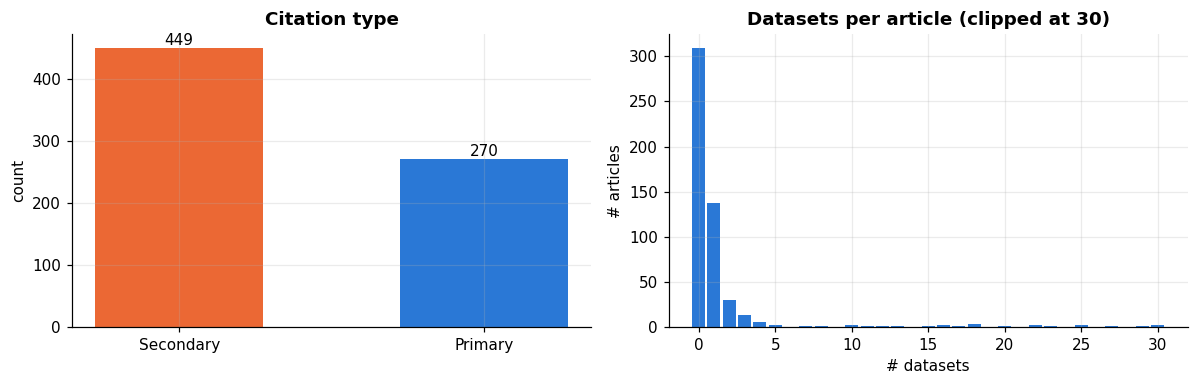

count    523.00
mean       1.37
std        4.15
min        0.00
25%        0.00
50%        0.00
75%        1.00
max       32.00
dtype: float64


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = gold["type"].value_counts()
ax[0].bar(vc.index, vc.values, color=[C[t] for t in vc.index], width=.55)
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v}", ha="center", va="bottom")
ax[0].set_title("Citation type"); ax[0].set_ylabel("count")

per_art = gold.groupby("article_id").size().reindex(labels.article_id.unique(), fill_value=0)
bins = np.arange(0, min(per_art.max(), 30) + 2) - .5
ax[1].hist(per_art.clip(upper=30), bins=bins, color=C["bar"], rwidth=.85)
ax[1].set_title("Datasets per article (clipped at 30)"); ax[1].set_xlabel("# datasets"); ax[1].set_ylabel("# articles")
plt.tight_layout(); plt.show()
print(per_art.describe().round(2))